# Filbin et al. 2018 — H3-K27M Glioma
## 04 · Module correlation along pseudotime (Gate 3, part 1)

On the **Mixed hub** (the module-convergence population at the branch point), compute the mutual
Gast<->pSom correlation in **pseudotime windows** (Puram-04 protocol: Gast XOR pSom genes, per-window
per-gene correlation to each module, then correlate the two loading vectors). Rendered as a
correlation UMAP: negative (blue) where the two programs cross-repress as cells commit to arms.

In [ ]:
import os, sys, re, glob, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import anndata as ad
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>  (two levels below Puram)
name = os.path.basename(os.getcwd())                    # e.g. Filbin2018_Brain-9  (attempt suffix)
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition (Brain)
dset = re.sub(r'-\d+$', '', name)                       # strip -N attempt suffix -> input folder key
pth  = os.path.join(*([os.pardir]*4))                 # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + dset)                       # raw input
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)   # h5ads
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
FEAT = os.path.join(pth_data, 'features', 'biomart')
print('dataset:', name, '| category:', cat)

dataset: Filbin2018_Brain-9 | category: Brain


### Load signatures

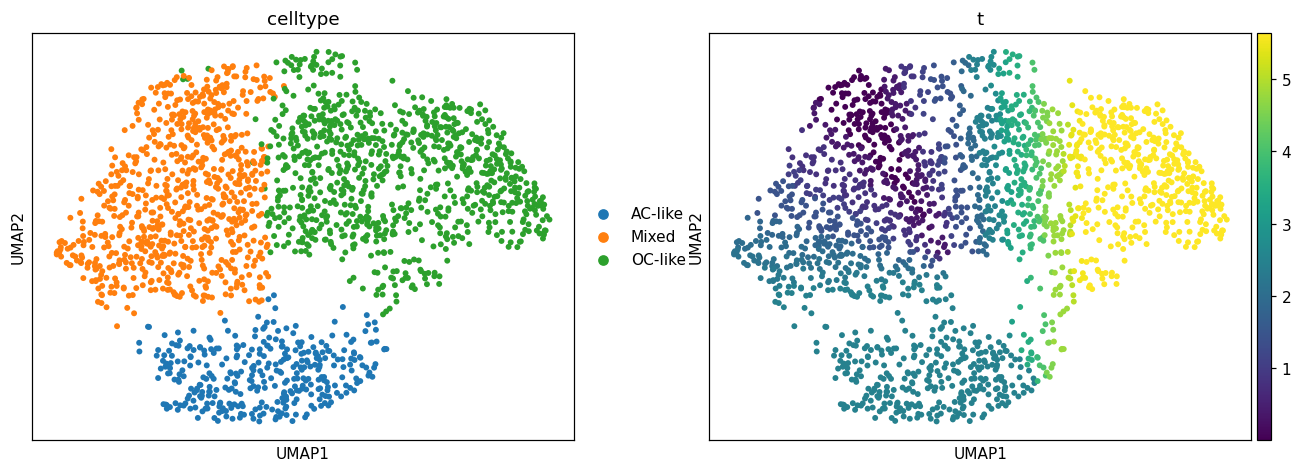

In [ ]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
sc.pl.umap(adata, color=['celltype', 't'], size=60); plt.show()

### Select module genes (Gast XOR pSom) and the Mixed hub
The XOR set isolates genes exclusive to one module (co-repression/cooperation readout). The hub is
the **Mixed** convergence population — identified by role (max Gast+pSom co-expression at the branch
point), confirmed as the topological convergence node in 02.

In [ ]:
get_feat = lambda p: set(pd.read_csv(p).hsapiens.dropna())
gast = get_feat(os.path.join(FEAT, 'GSE162534.csv'))
psom = get_feat(os.path.join(FEAT, 'GSE229103.csv'))
g = pd.Series(list(gast ^ psom)); g = g[g.isin(adata.var_names)]
print('Gast XOR pSom genes in data:', g.size)
adata_corr = adata[adata.obs.celltype == 'Mixed', g].copy()
print('Mixed hub cells:', adata_corr.n_obs)

Gast XOR pSom genes in data: 121
Mixed hub cells: 761


### Pseudotime-windowed mutual correlation

In [ ]:
n_cells = 60; t = adata_corr.obs.t
n_bins = max(3, t.size // n_cells)
t_bin = pd.cut(t, bins=n_bins); adata_corr.obs['t_bin'] = t_bin
grp = adata_corr.obs.groupby('t_bin', observed=True)
r_dict = {}
for b, sdf in grp:
    ab = adata_corr[sdf.index].copy()
    X = pd.DataFrame(ab.X.toarray(), index=sdf.index, columns=g)
    X = X.loc[:, X.nunique(axis=0) > 1]
    a = pearsonr(X, sdf.GSE162534.values[:, None], axis=0).statistic
    b2 = pearsonr(X, sdf.GSE229103.values[:, None], axis=0).statistic
    r_dict[b] = np.corrcoef(a, b2)[0, 1]
A = adata_corr.obsp['connectivities']
R = t_bin.map(r_dict).astype(float)
R_sm = (A @ R) / A.sum(axis=1).A1
adata_corr.obs['correlation'] = R_sm
print('windowed r per bin:', {str(round(k.mid,2)): round(v,3) for k, v in r_dict.items()})
print('smoothed correlation range: %.3f to %.3f' % (np.nanmin(R_sm), np.nanmax(R_sm)))

windowed r per bin: {'0.11': np.float64(0.359), '0.32': np.float64(0.077), '0.72': np.float64(0.112), '0.93': np.float64(0.181), '1.13': np.float64(-0.029), '1.33': np.float64(0.015), '1.54': np.float64(-0.183), '1.74': np.float64(0.045), '1.94': np.float64(-0.276), '2.15': np.float64(-0.354), '2.35': np.float64(-0.476)}
smoothed correlation range: -0.476 to 0.353


### `correlation.pdf` — module correlation UMAP (+ colorbar)
Blue (negative) at the hub/commitment zone = Gast<->pSom cross-repression as cells diverge.

saved correlation.pdf


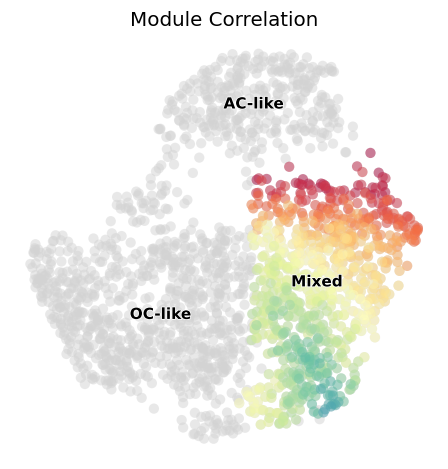

In [ ]:
vlim = .5
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
sc.pl.umap(adata, size=180, alpha=.5, frameon=False, show=False, ax=ax)
sc.pl.umap(adata_corr, color='correlation', cmap='Spectral', vmin=-vlim, vmax=vlim,
           size=180, alpha=.5, colorbar_loc=None, frameon=False, show=False, ax=ax)
sc.pl.umap(adata, color='celltype', size=180, alpha=0, legend_loc='on data',
           legend_fontoutline=1, frameon=False, show=False, ax=ax)
ax.invert_yaxis(); ax.invert_xaxis()
ax.set_title('Module Correlation', size=13)
fig.savefig(os.path.join(pth_fig, 'correlation.pdf'), bbox_inches='tight'); plt.show()
print('saved correlation.pdf')

saved colorbars/R_colorbar.pdf


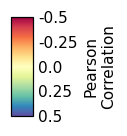

In [ ]:
fig = plt.figure(figsize=(.66, 1))
cax = fig.add_axes([.35, .05, .3, .9])
cb = plt.colorbar(ax.collections[1], cax=cax)
cb.ax.tick_params(which='both', size=0)
cb.set_label('Pearson\nCorrelation'); cb.ax.invert_yaxis()
ticks = np.asarray([-.5, -.25, 0, .25, .5])
cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
fig.savefig(os.path.join(pth_cb, 'R_colorbar.pdf'), bbox_inches='tight'); plt.show()
print('saved colorbars/R_colorbar.pdf')